In [3]:
import kagglehub
import os 
# Download latest version
path = kagglehub.dataset_download("srisyra02/air-quality-dataset")
filename = os.listdir(path)[0]
filename = os.path.join(path,filename)
print("Path to dataset files:", filename)

Using Colab cache for faster access to the 'air-quality-dataset' dataset.
Path to dataset files: /kaggle/input/air-quality-dataset/air_quality_dataset.csv


# All library in this project

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

BLUE, ORANGE = "#3b6ea5", "#e07a5f"
cols = data.columns.tolist()

In [5]:
data = pd.read_csv(filename)
data

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835
...,...,...,...,...,...,...,...,...,...,...
495,51.380025,57.573550,31.124630,19.276010,11.167098,104.071502,1.844483,397.418878,1.923525,34.323410
496,46.816837,75.372133,22.174014,18.535162,12.169426,74.802208,1.364096,392.316075,2.157281,26.321361
497,33.909351,88.097250,27.630317,15.653370,7.997326,128.105470,2.319453,378.653347,1.809489,28.964494
498,43.721651,40.847991,27.253977,19.365916,7.218154,106.053329,1.599748,389.878566,1.858964,29.976442


In [7]:
data.describe()

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,54.671620,84.703251,91.814080,42.410820,11.504816,112.193098,2.177705,439.288087,2.130439,30.448413
std,22.799473,30.567912,54.808414,26.343669,7.306978,39.471686,0.824762,51.220578,0.391396,2.957290
min,10.757597,12.932337,-0.076323,-1.942140,-1.095555,27.555617,0.366992,366.063158,1.388407,19.581349
25%,36.372940,61.118607,35.457263,17.448632,5.976492,81.516729,1.536915,397.399610,1.837395,28.481974
50%,48.038599,78.135558,95.452284,39.211583,8.681222,104.819124,2.045519,420.934319,2.066709,30.432756
75%,73.820566,110.270086,134.709240,63.817763,17.116673,140.588100,2.726020,490.968315,2.386267,32.614954
max,127.616632,171.594187,225.886935,115.916428,31.941860,231.926017,4.798935,558.924256,3.352266,39.778713


In [ ]:
# Takeaways from data.describe()
#
# Size and completeness
# Every column has count = 500, so there are no missing values in this
# table. Still worth confirming with isnull().sum() in the earlier cell.
#
# Negative values
# NOx (min -0.08), NO2 (min -1.94) and SO2 (min -1.10) have negative
# minimums. A concentration can't be below zero, so these are either
# sensor noise or a side effect of how the data was generated (it looks
# synthetic). They are few and small, but I should count them and decide
# whether to clip them to 0 or leave them.
#
# Skewness (mean vs median)
# PM2.5 (54.7 vs 48.0), PM10 (84.7 vs 78.1), SO2 (11.5 vs 8.7) and VOCs
# (112.2 vs 104.8) have a mean clearly above the median, which points to
# a right tail. CO2 and CH4 show the same pattern but weaker.
# NOx goes the other way (mean 91.8, median 95.5) and has a huge spread
# (std 54.8, range about 0 to 226), so its histogram is probably wide and
# flat rather than bell-shaped. Temperature has mean and median almost
# equal (30.45 vs 30.43), so it looks symmetric.
#
# Spread and scale
# The columns live on very different scales: CO2 is in the hundreds
# (366 to 559) while CH4 is around 1.4 to 3.4 and CO around 0.4 to 4.8.
# If I use distance-based models or regularization later, I need to
# standardize first.
#
# Relationships that already show up
# PM10 is higher than PM2.5 in mean, median and max, which is what I
# expect because PM10 includes the finer particles. The same goes for
# NOx vs NO2 (NO2 is a part of NOx).
# I should also check row by row if PM10 < PM2.5 ever happens, since
# that would be physically odd.
#
# Temperature
# Ranges from 19.6 to 39.8 with std about 3, so it's the most compact
# column relative to its mean. It's a reasonable target if I want a model.
#
# Next steps
# - count negatives per column and decide how to handle them
# - check skew() and the IQR outlier counts to see which tails are real
# - compare Pearson and Spearman correlations

In [9]:
neg = (data < 0).sum()
print("Negative values:\n", neg[neg > 0], "\n")
print("PM10 < PM2.5:", (data["PM10"] < data["PM2.5"]).sum())
print("NO2 > NOx:", (data["NO2"] > data["NOx"]).sum())

Negative values:
 NOx    1
NO2    1
SO2    2
dtype: int64 

PM10 < PM2.5: 36
NO2 > NOx: 21


# Distributions

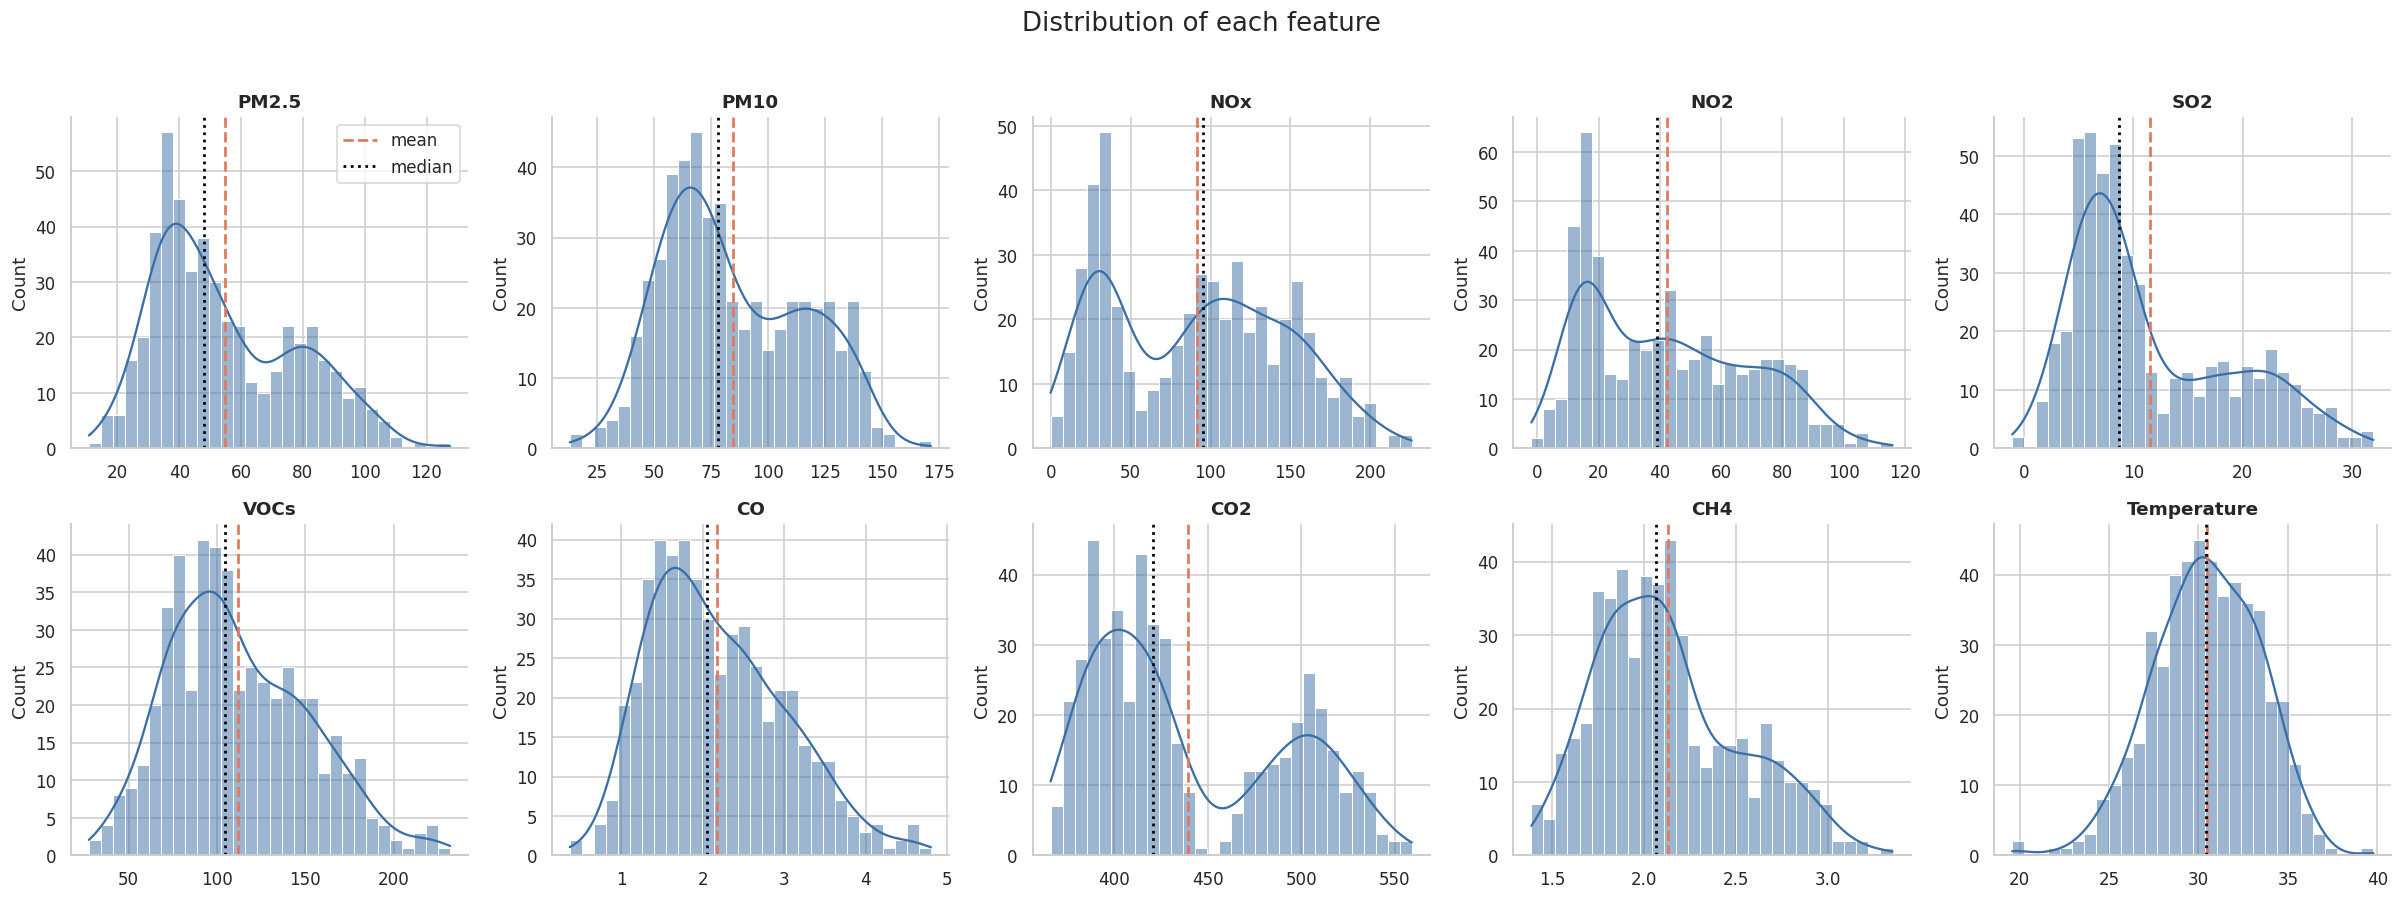

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(data[col], kde=True, bins=30, color=BLUE, edgecolor="white", ax=ax)
    ax.axvline(data[col].mean(), color=ORANGE, ls="--", lw=1.8, label="mean")
    ax.axvline(data[col].median(), color="black", ls=":", lw=1.8, label="median")
    ax.set_title(col, fontweight="bold")
    ax.set_xlabel("")
axes[0, 0].legend()
fig.suptitle("Distribution of each feature", fontsize=17, y=1.02)
plt.tight_layout()
plt.show()

In [11]:
shape = pd.DataFrame({"skew": data.skew(), "kurtosis": data.kurt()})
shape["shapiro_p"] = [stats.shapiro(data[c])[1] for c in cols]
shape.sort_values("skew").round(3)

,skew,kurtosis,shapiro_p
Temperature,-0.247,0.147,0.069
NOx,0.164,-1.102,0.000
PM10,0.356,-0.829,0.000
NO2,0.446,-0.925,0.000
VOCs,0.500,-0.191,0.000
CO2,0.547,-1.131,0.000
CO,0.591,-0.117,0.000
CH4,0.599,-0.261,0.000
PM2.5,0.610,-0.560,0.000
SO2,0.845,-0.405,0.000


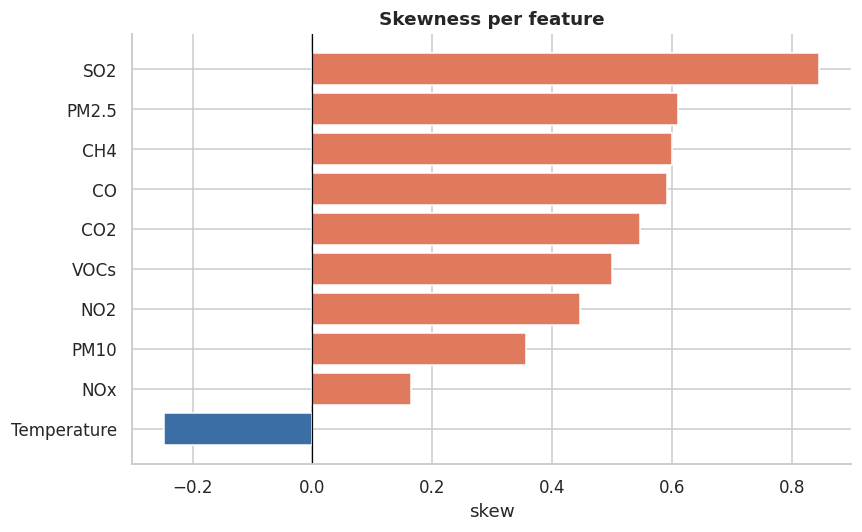

In [12]:
skew = data.skew().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(skew.index, skew.values, color=[ORANGE if v > 0 else BLUE for v in skew.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Skewness per feature", fontweight="bold")
ax.set_xlabel("skew")
plt.tight_layout()
plt.show()

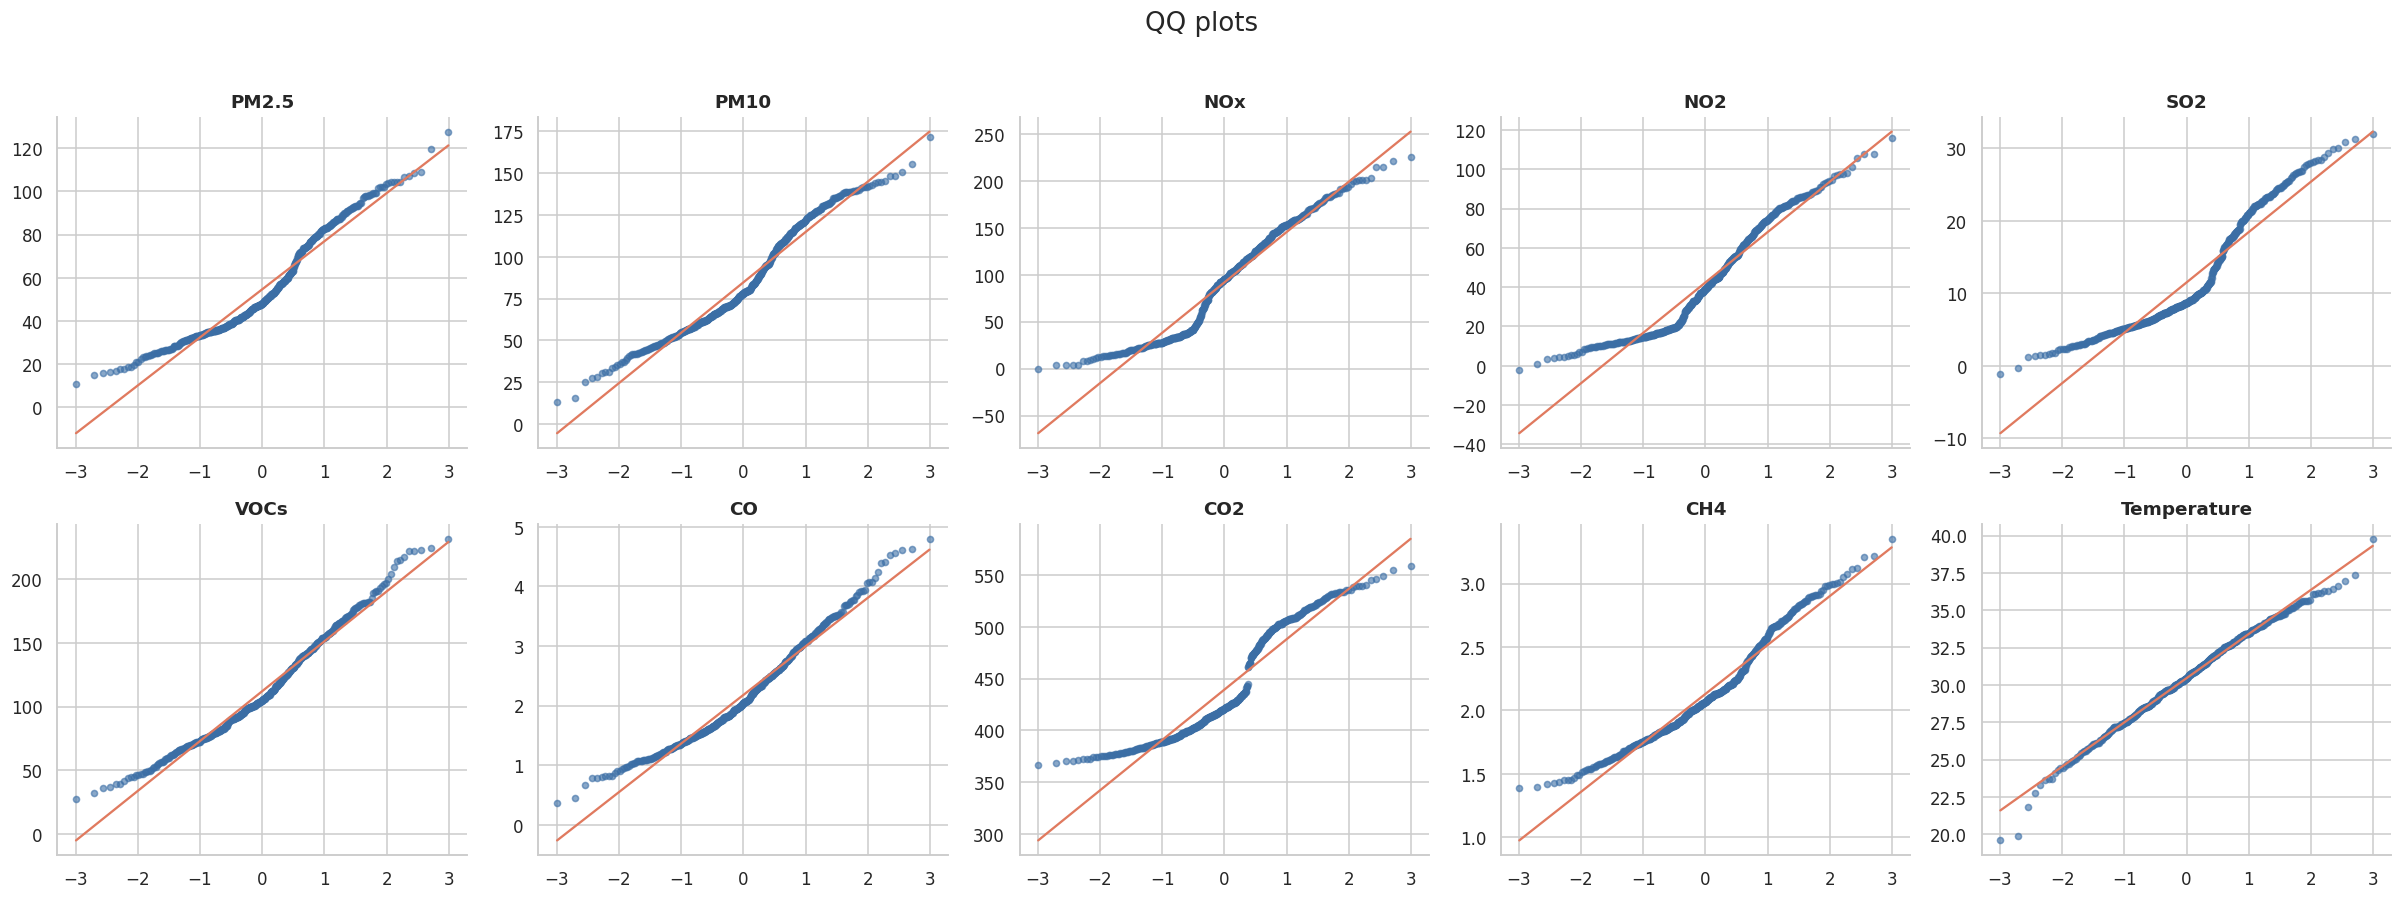

In [13]:
# QQ plots against a normal distribution
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), cols):
    stats.probplot(data[col], dist="norm", plot=ax)
    pts, line = ax.get_lines()
    pts.set(markerfacecolor=BLUE, markeredgecolor=BLUE, markersize=4, alpha=0.6)
    line.set_color(ORANGE)
    ax.set_title(col, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("QQ plots", fontsize=17, y=1.02)
plt.tight_layout()
plt.show()

# Outliers

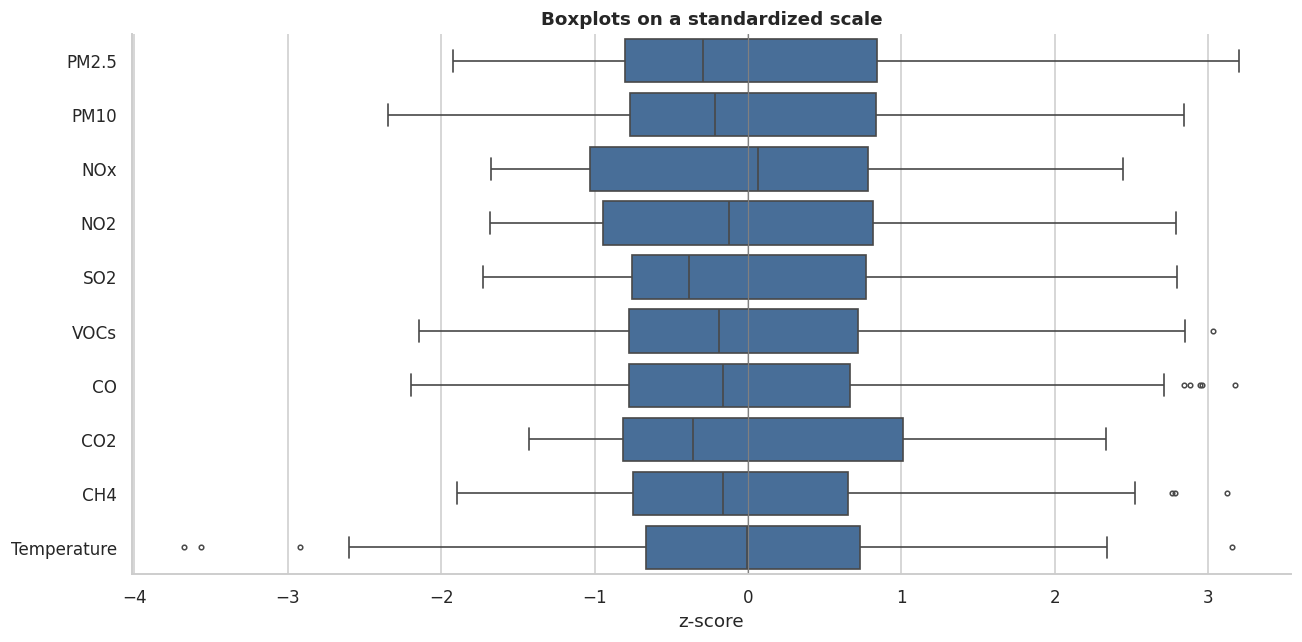

In [14]:
# z-scores so every column fits on one axis
z = (data - data.mean()) / data.std()

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=z, orient="h", color=BLUE, fliersize=3, linewidth=1.1, ax=ax)
ax.axvline(0, color="grey", lw=0.8)
ax.set_title("Boxplots on a standardized scale", fontweight="bold")
ax.set_xlabel("z-score")
plt.tight_layout()
plt.show()

In [15]:
q1, q3 = data.quantile(0.25), data.quantile(0.75)
iqr = q3 - q1
mask = (data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)

out = pd.DataFrame({"outliers": mask.sum(), "pct": (mask.mean() * 100).round(2)})
out.sort_values("outliers", ascending=False)

,outliers,pct
CO,5,1.0
Temperature,4,0.8
CH4,3,0.6
VOCs,1,0.2
PM10,0,0.0
PM2.5,0,0.0
SO2,0,0.0
NO2,0,0.0
NOx,0,0.0
CO2,0,0.0


# Correlation

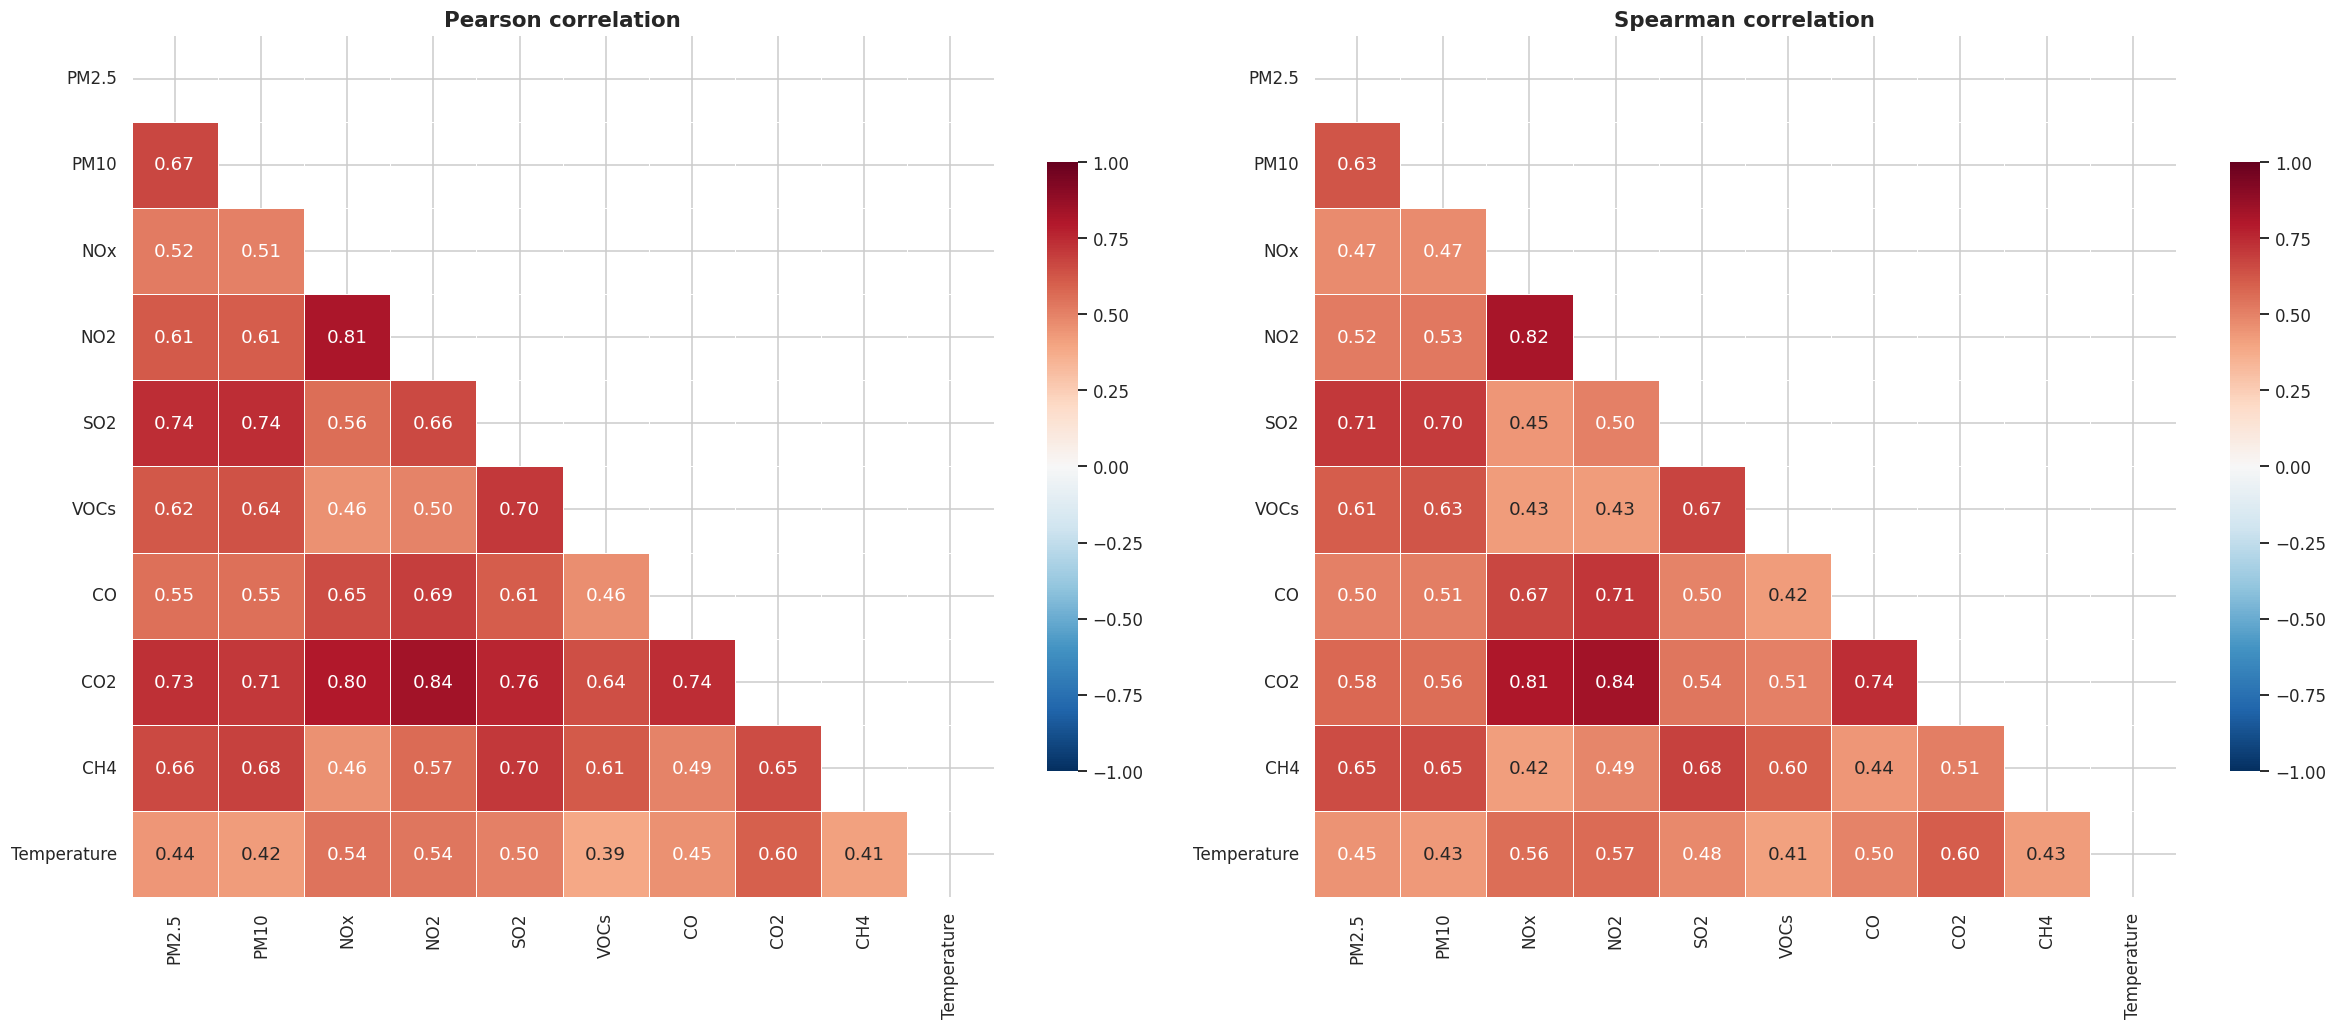

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = data.corr(method=method)
    upper = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=upper, annot=True, fmt=".2f", cmap="RdBu_r",
                center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
                cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title(f"{method.title()} correlation", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Temperature vs Other Features

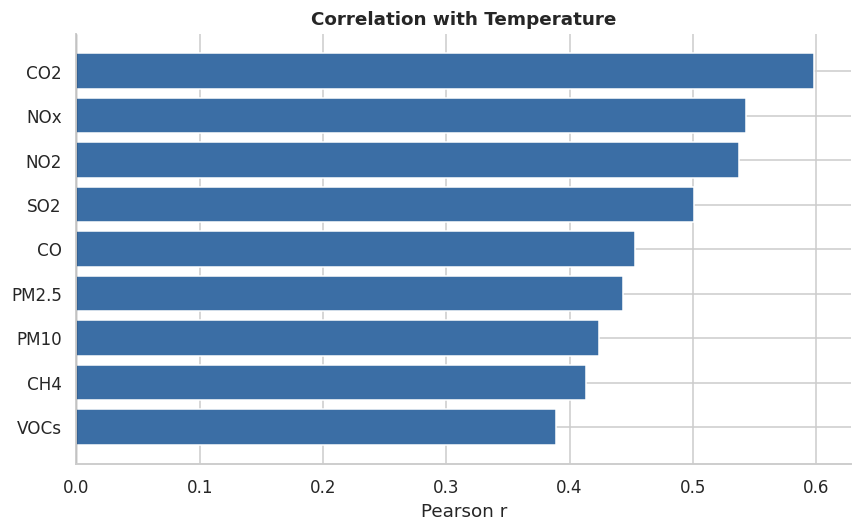

In [21]:
temp_corr = data.corr()["Temperature"].drop("Temperature").sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(temp_corr.index, temp_corr.values,
        color=[BLUE if v > 0 else ORANGE for v in temp_corr.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlation with Temperature", fontweight="bold")
ax.set_xlabel("Pearson r")
plt.tight_layout()
plt.show()

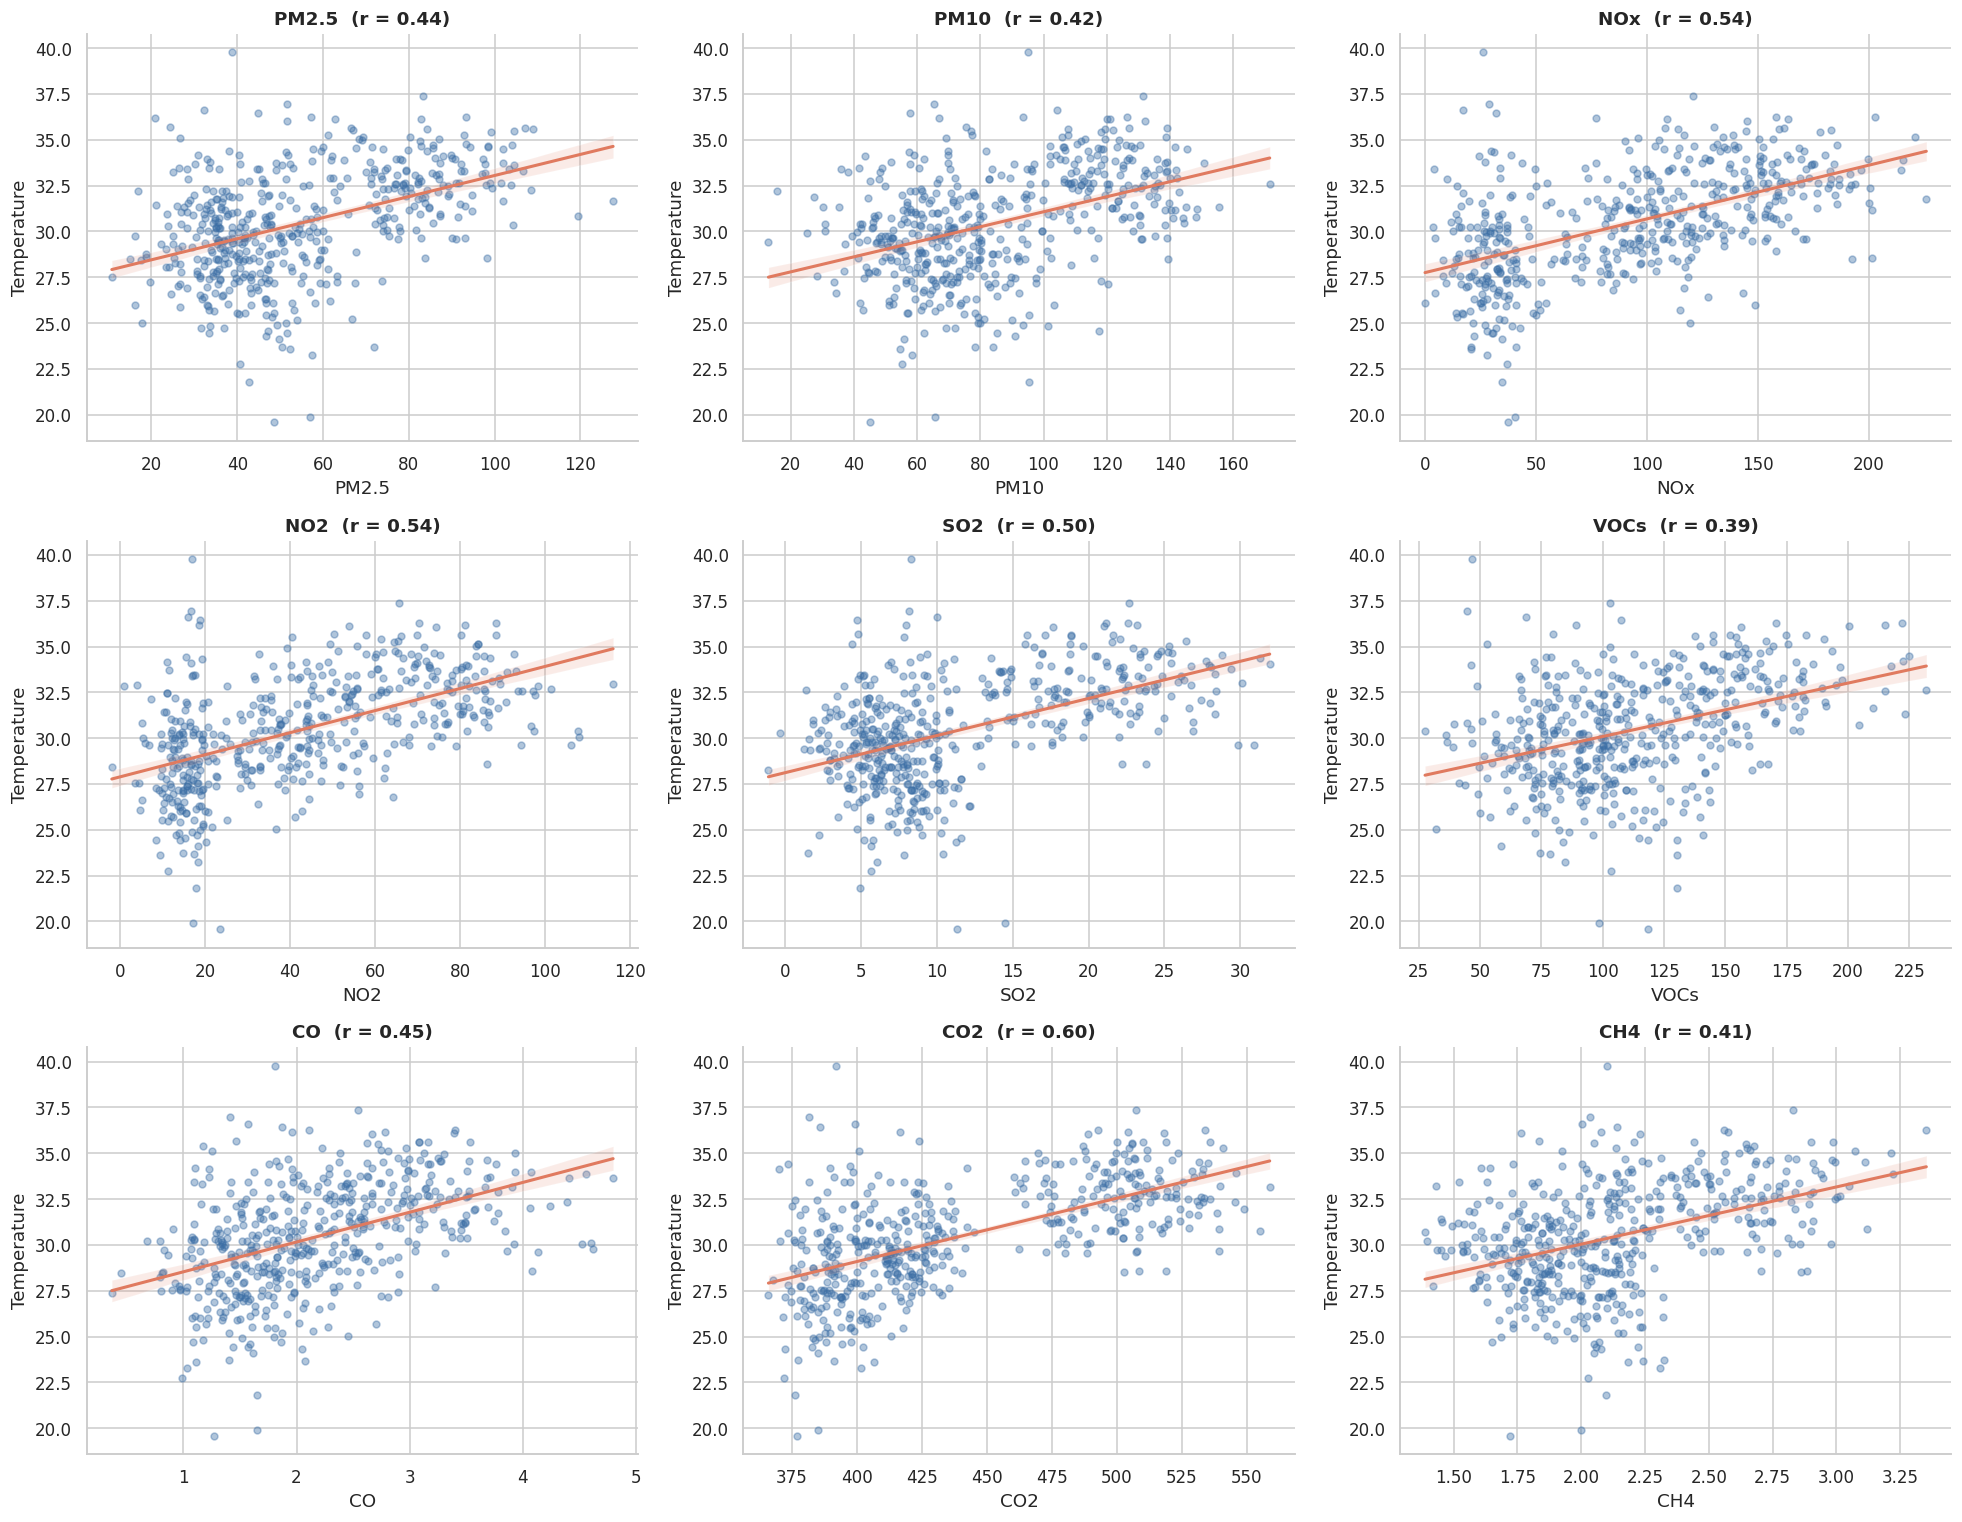

In [19]:
feats = [c for c in cols if c != "Temperature"]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), feats):
    sns.regplot(data=data, x=col, y="Temperature", ax=ax,
                scatter_kws={"alpha": 0.4, "s": 20, "color": BLUE},
                line_kws={"color": ORANGE, "lw": 2})
    ax.set_title(f"{col}  (r = {data[col].corr(data['Temperature']):.2f})", fontweight="bold")
plt.tight_layout()
plt.show()

# Pairplot

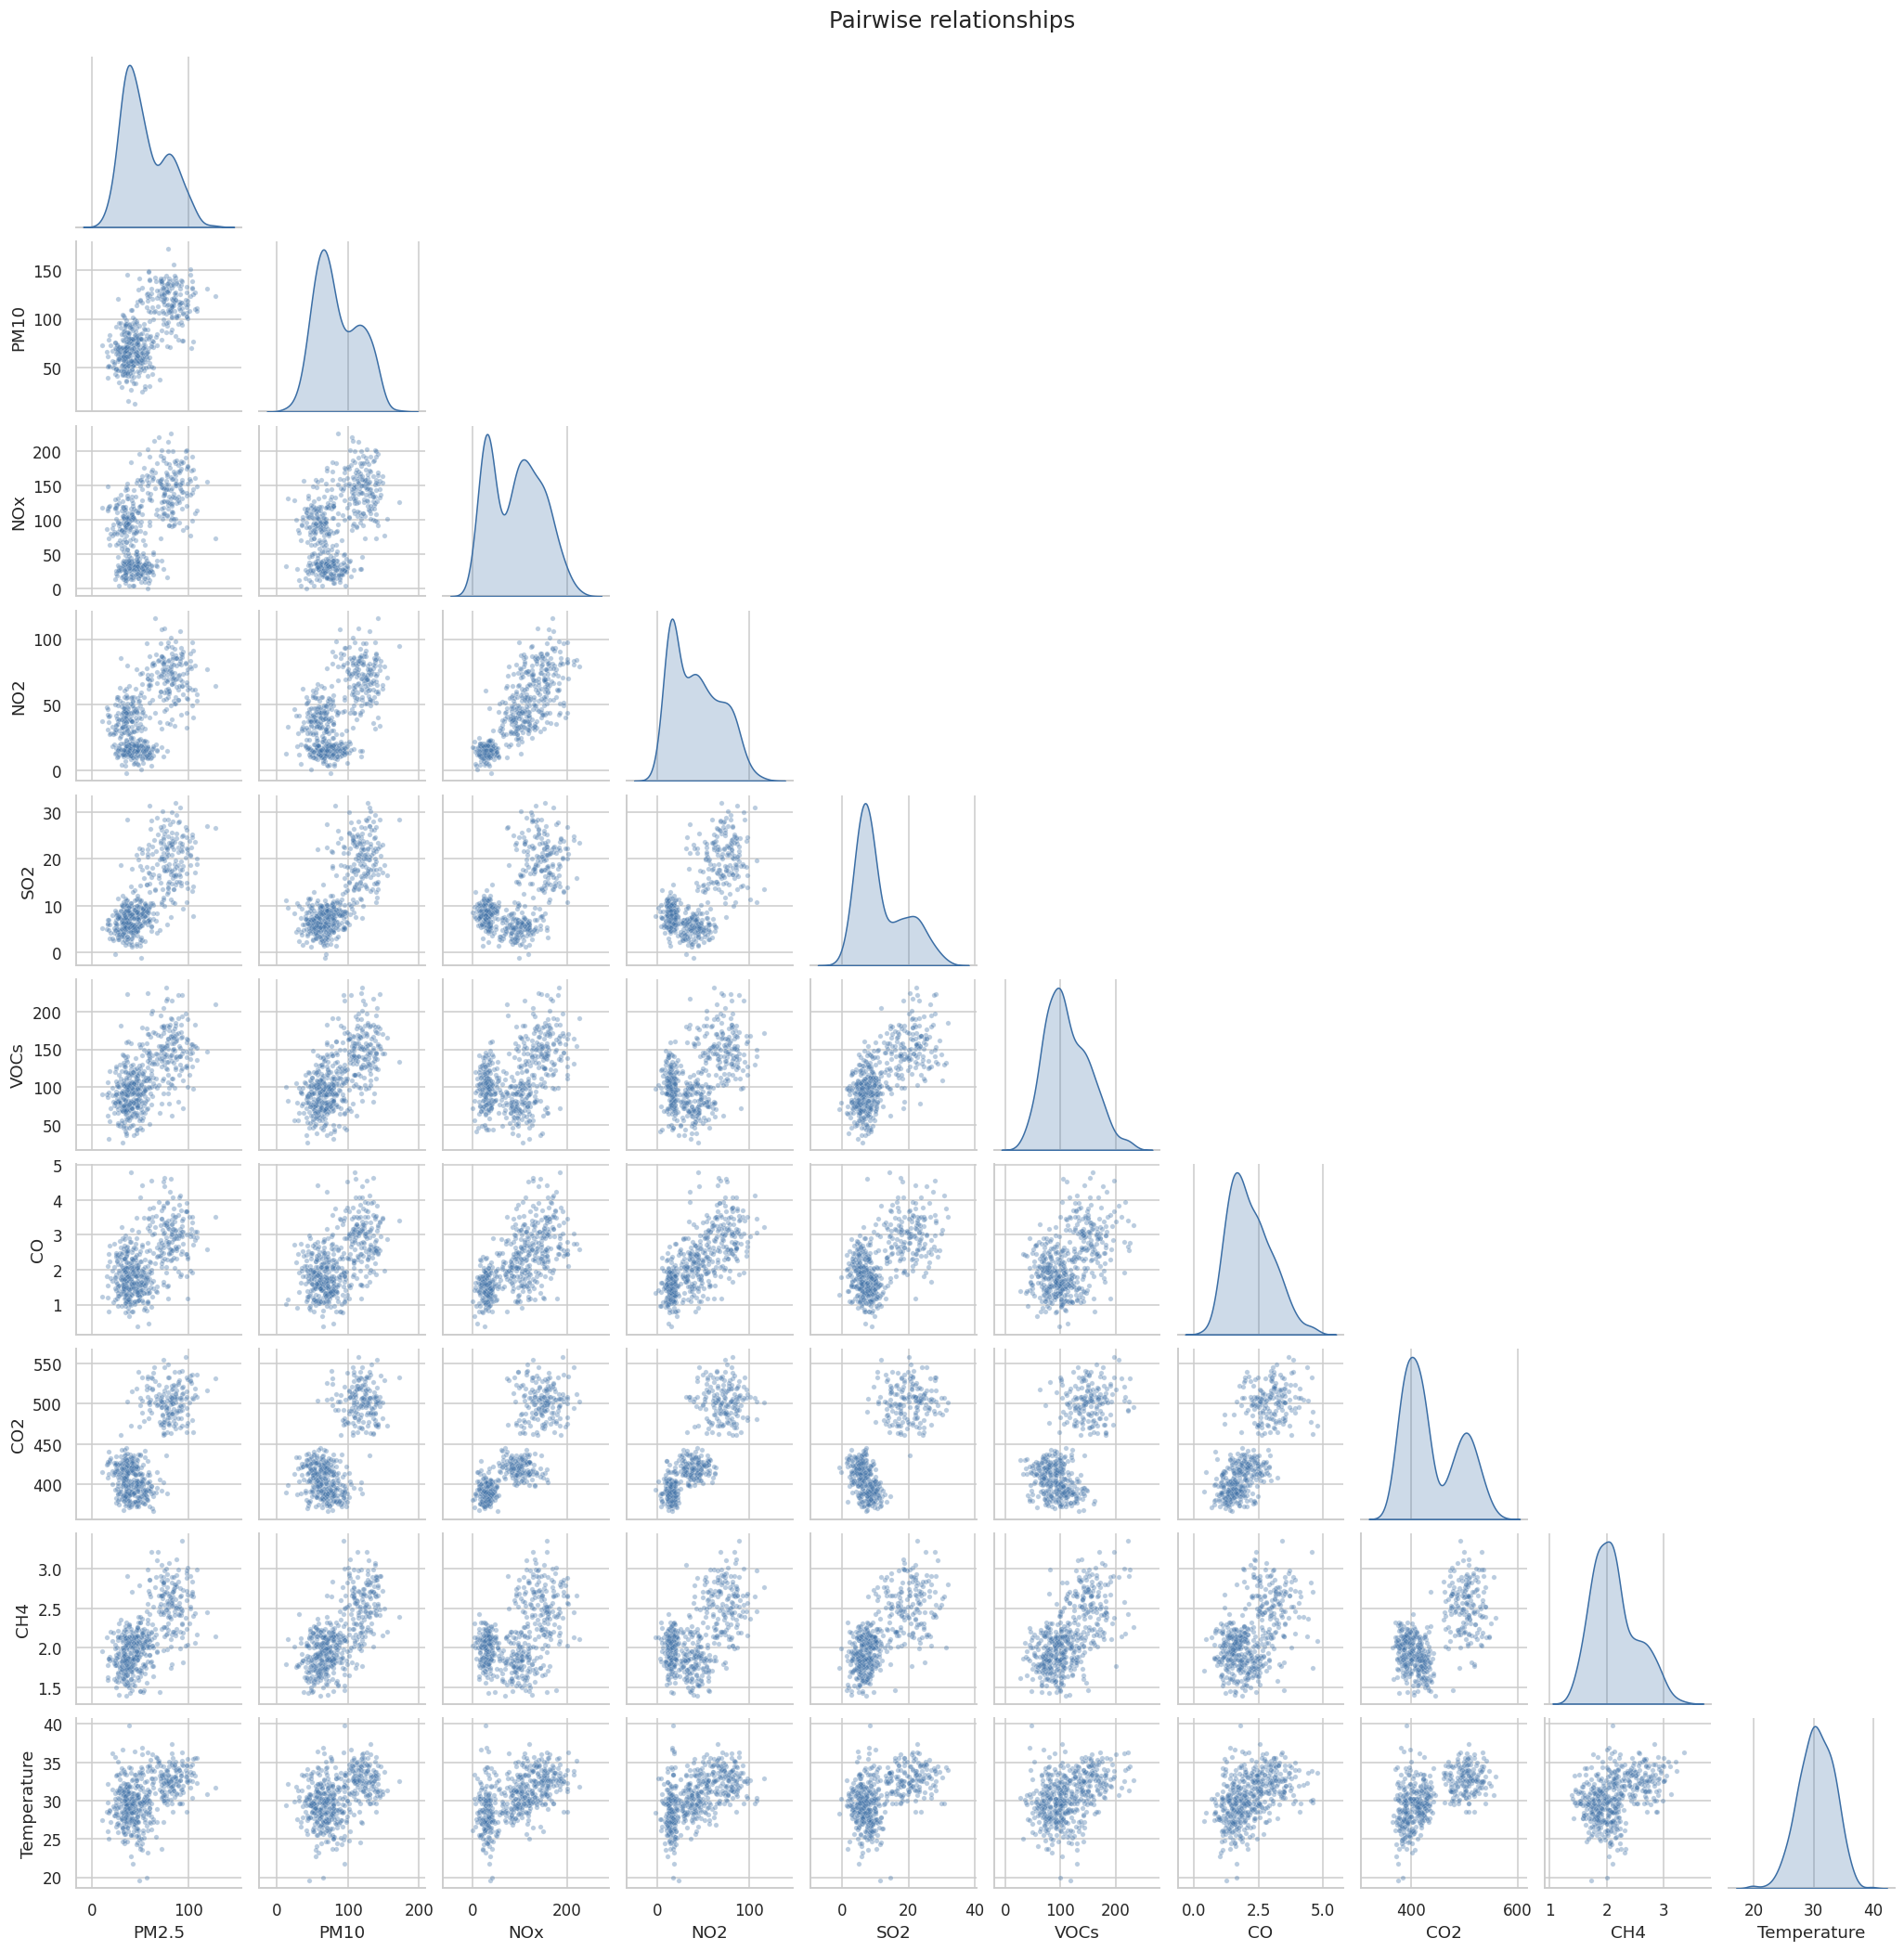

In [20]:
g = sns.pairplot(data, corner=True, diag_kind="kde", height=1.9,
                 plot_kws={"alpha": 0.35, "s": 12, "color": BLUE},
                 diag_kws={"color": BLUE, "fill": True})
g.figure.suptitle("Pairwise relationships", y=1.01, fontsize=16)
plt.show()

# Multicollinearity (VIF)

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X = add_constant(data.drop(columns="Temperature"))
vif = pd.DataFrame({
    "feature": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
})
vif = vif[vif["feature"] != "const"].sort_values("VIF", ascending=False)
vif.round(2)

,feature,VIF
8,CO2,6.96
4,NO2,4.39
5,SO2,3.79
3,NOx,3.69
1,PM2.5,2.81
2,PM10,2.79
9,CH4,2.44
7,CO,2.34
6,VOCs,2.28
